# How to Train YOLOv9 on a Custom Dataset
---

[![Roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/train-yolov9-model/)
[![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/WongKinYiu/yolov9)
[![YouTube](https://badges.aleen42.com/src/youtube.svg)](https://youtu.be/XHT2c8jT3Bc)
[![arXiv](https://img.shields.io/badge/arXiv-2402.13616-b31b1b.svg)](https://arxiv.org/pdf/2402.13616.pdf)

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

Fri Sep 20 01:37:44 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   32C    P0              47W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
# Ensure colab doesn't disconnect
%%javascript
function ClickConnect(){
console.log("Working");
document.querySelector("colab-toolbar-button").click()
}setInterval(ClickConnect,300000)

<IPython.core.display.Javascript object>

In [3]:
!git clone https://github.com/SkalskiP/yolov9.git
%cd yolov9
!pip install -r requirements.txt -q

Cloning into 'yolov9'...
remote: Enumerating objects: 325, done.
remote: Total 325 (delta 0), reused 0 (delta 0), pack-reused 325 (from 1)
Receiving objects: 100% (325/325), 2.25 MiB | 12.17 MiB/s, done.
Resolving deltas: 100% (162/162), done.
/content/yolov9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 4.7 MB/s eta 0:00:00


In [4]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.1 MB/s eta 0:00:00


In [5]:
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-e.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-e.pt

In [6]:
!ls -la {HOME}/weights

total 402440
drwxr-xr-x 2 root root      4096 Sep 20 01:37 .
drwxr-xr-x 1 root root      4096 Sep 20 01:37 ..
-rw-r--r-- 1 root root  51508261 Feb 18  2024 gelan-c.pt
-rw-r--r-- 1 root root 117203713 Feb 18  2024 gelan-e.pt
-rw-r--r-- 1 root root 103153312 Feb 18  2024 yolov9-c.pt
-rw-r--r-- 1 root root 140217688 Feb 18  2024 yolov9-e.pt


**NOTE:** The dataset must be saved inside the `{HOME}/yolov9` directory, otherwise, the training will not succeed.

In [7]:
%cd {HOME}/yolov9

/content/yolov9


**NOTE:** In this tutorial, I will use the [football-players-detection](https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc) dataset. Feel free to replace it with your dataset in YOLO format or use another dataset available on [Roboflow Universe](https://universe.roboflow.com). Additionally, if you plan to deploy your model to Roboflow after training, make sure you are the owner of the dataset and that no model is associated with the version of the dataset you are going to training on.

In [8]:
# import roboflow

# roboflow.login()

# rf = roboflow.Roboflow()

# project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
# version = project.version(8)
# dataset = version.download("yolov9")
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("kaohsiung_save-m3ojd")
version = project.version(3)
dataset = version.download("yolov9")



loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Kaohsiung_SAVE-3 in yolov9:: 100%|██████████| 8262/8262 [00:01<00:00, 6730.63it/s]


## Train Custom Model

In [ ]:
%cd {HOME}/yolov9

!python train.py \
--batch 16 --epochs 400 --img 640 --device 0 --min-items 0 --close-mosaic 15 \
--data {dataset.location}/data.yaml \
--cfg models/detect/gelan-c.yaml \
--hyp hyp.scratch-high.yaml

/content/yolov9
2024-06-26 10:07:44.114260: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-06-26 10:07:44.165502: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-26 10:07:44.165568: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-26 10:07:44.167122: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-06-26 10:07:44.175006: I tensorflow/core/platform/

## Examine Training Results

**NOTE:** By default, the results of each subsequent training sessions are saved in `{HOME}/yolov9/runs/train/`, in directories named `exp`, `exp2`, `exp3`, ... You can override this behavior by using the `--name` parameter.

In [ ]:
!ls {HOME}/yolov9/runs/train/exp/

confusion_matrix.png				    PR_curve.png	   val_batch0_pred.jpg
events.out.tfevents.1719396466.510923e15834.1878.0  R_curve.png		   val_batch1_labels.jpg
F1_curve.png					    results.csv		   val_batch1_pred.jpg
hyp.yaml					    results.png		   val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch0.jpg	   val_batch2_pred.jpg
labels.jpg					    train_batch1.jpg	   weights
opt.yaml					    train_batch2.jpg
P_curve.png					    val_batch0_labels.jpg


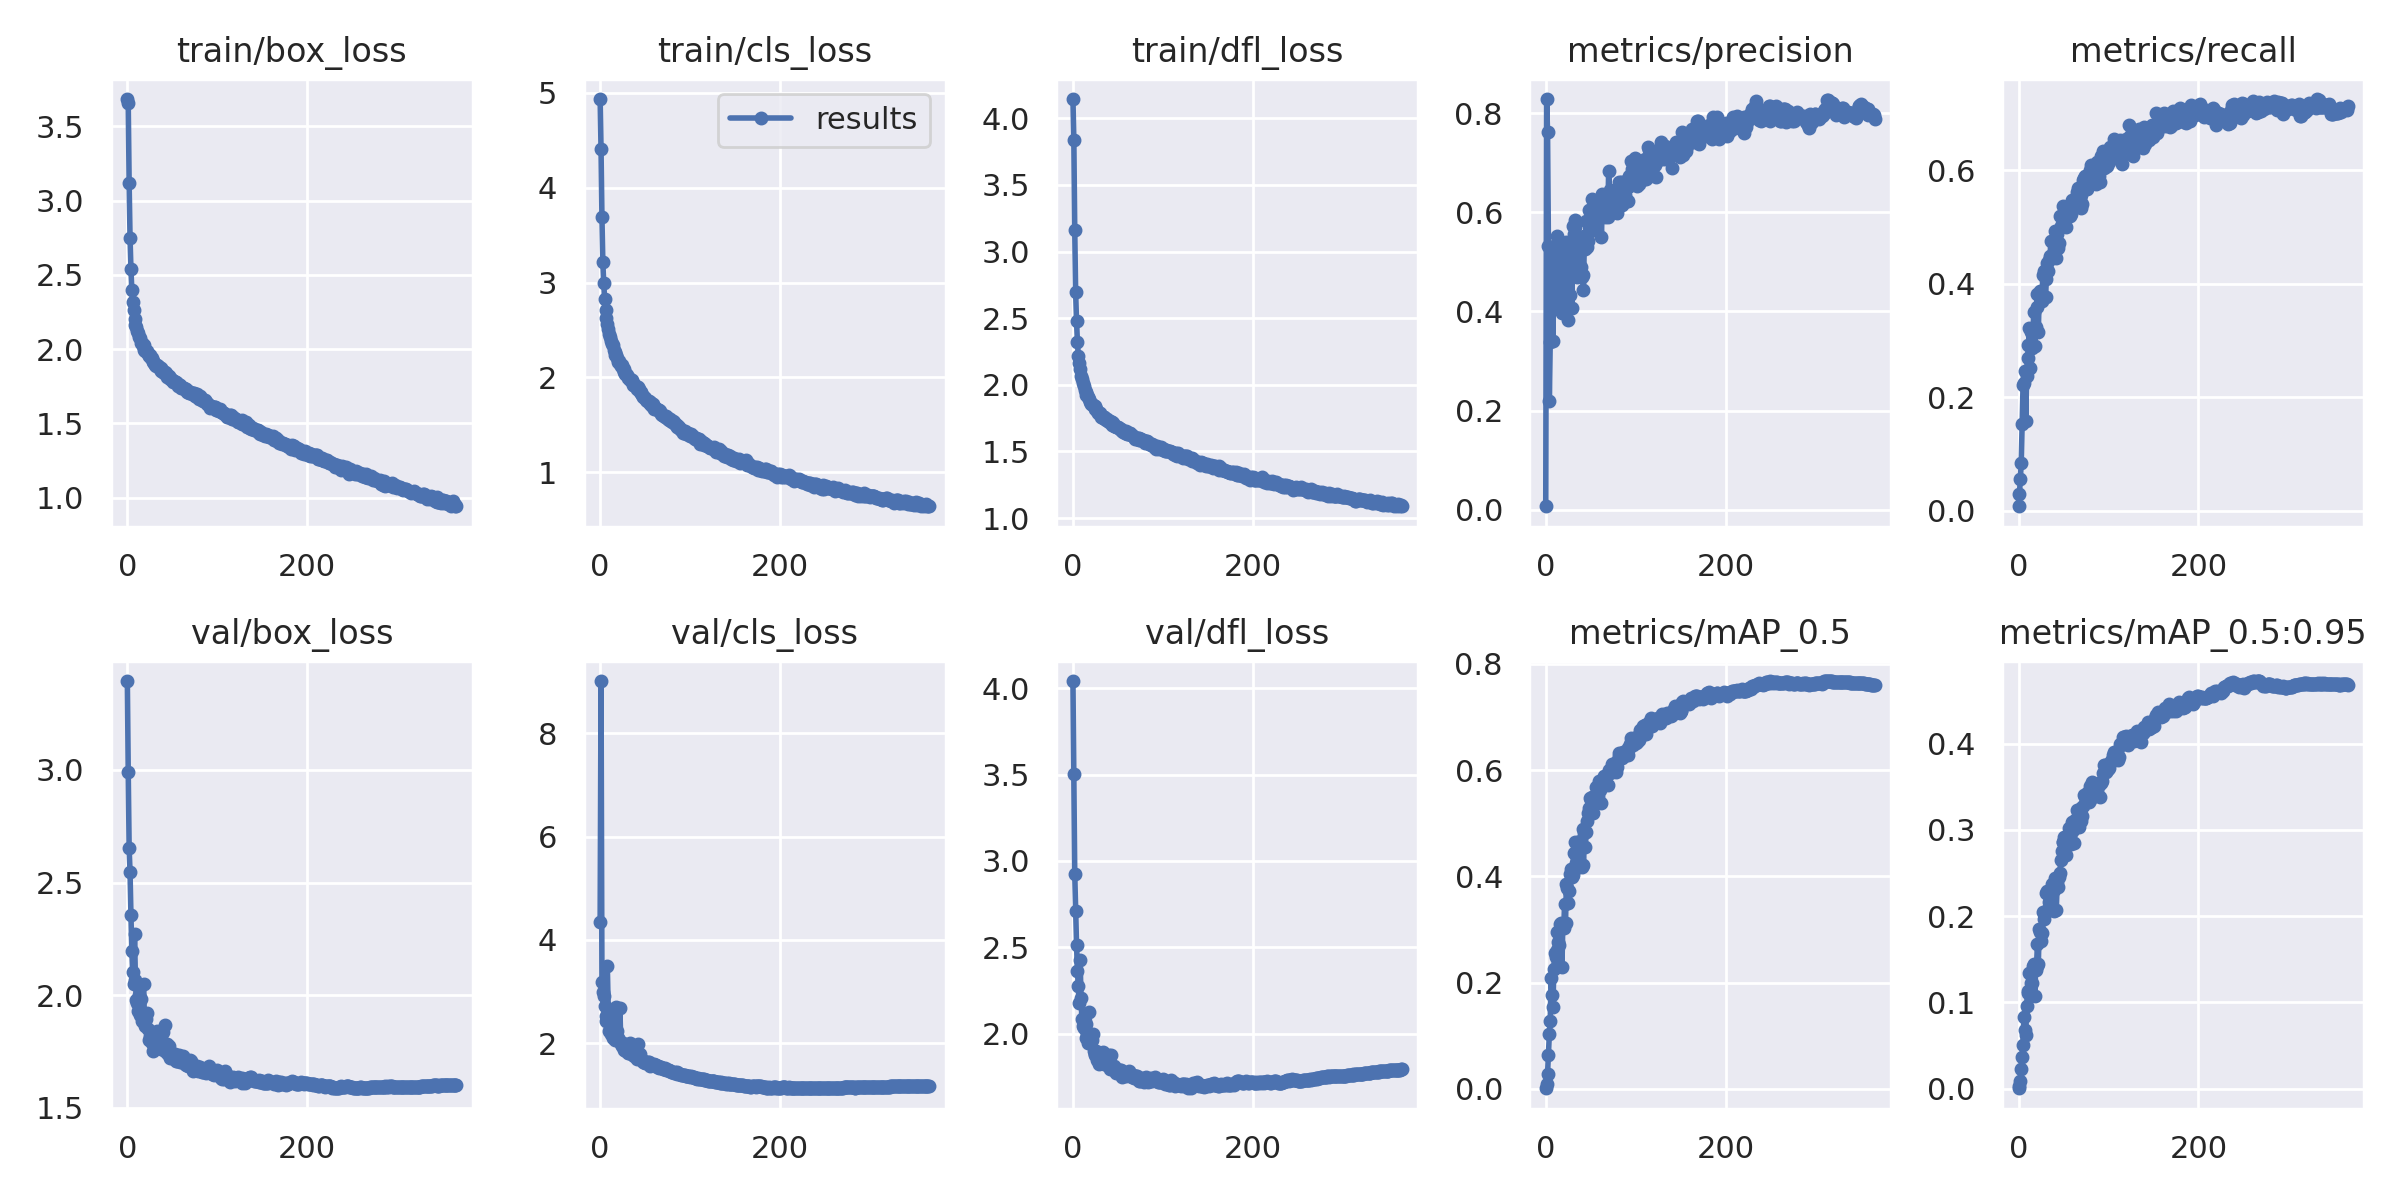

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/results.png", width=1000)

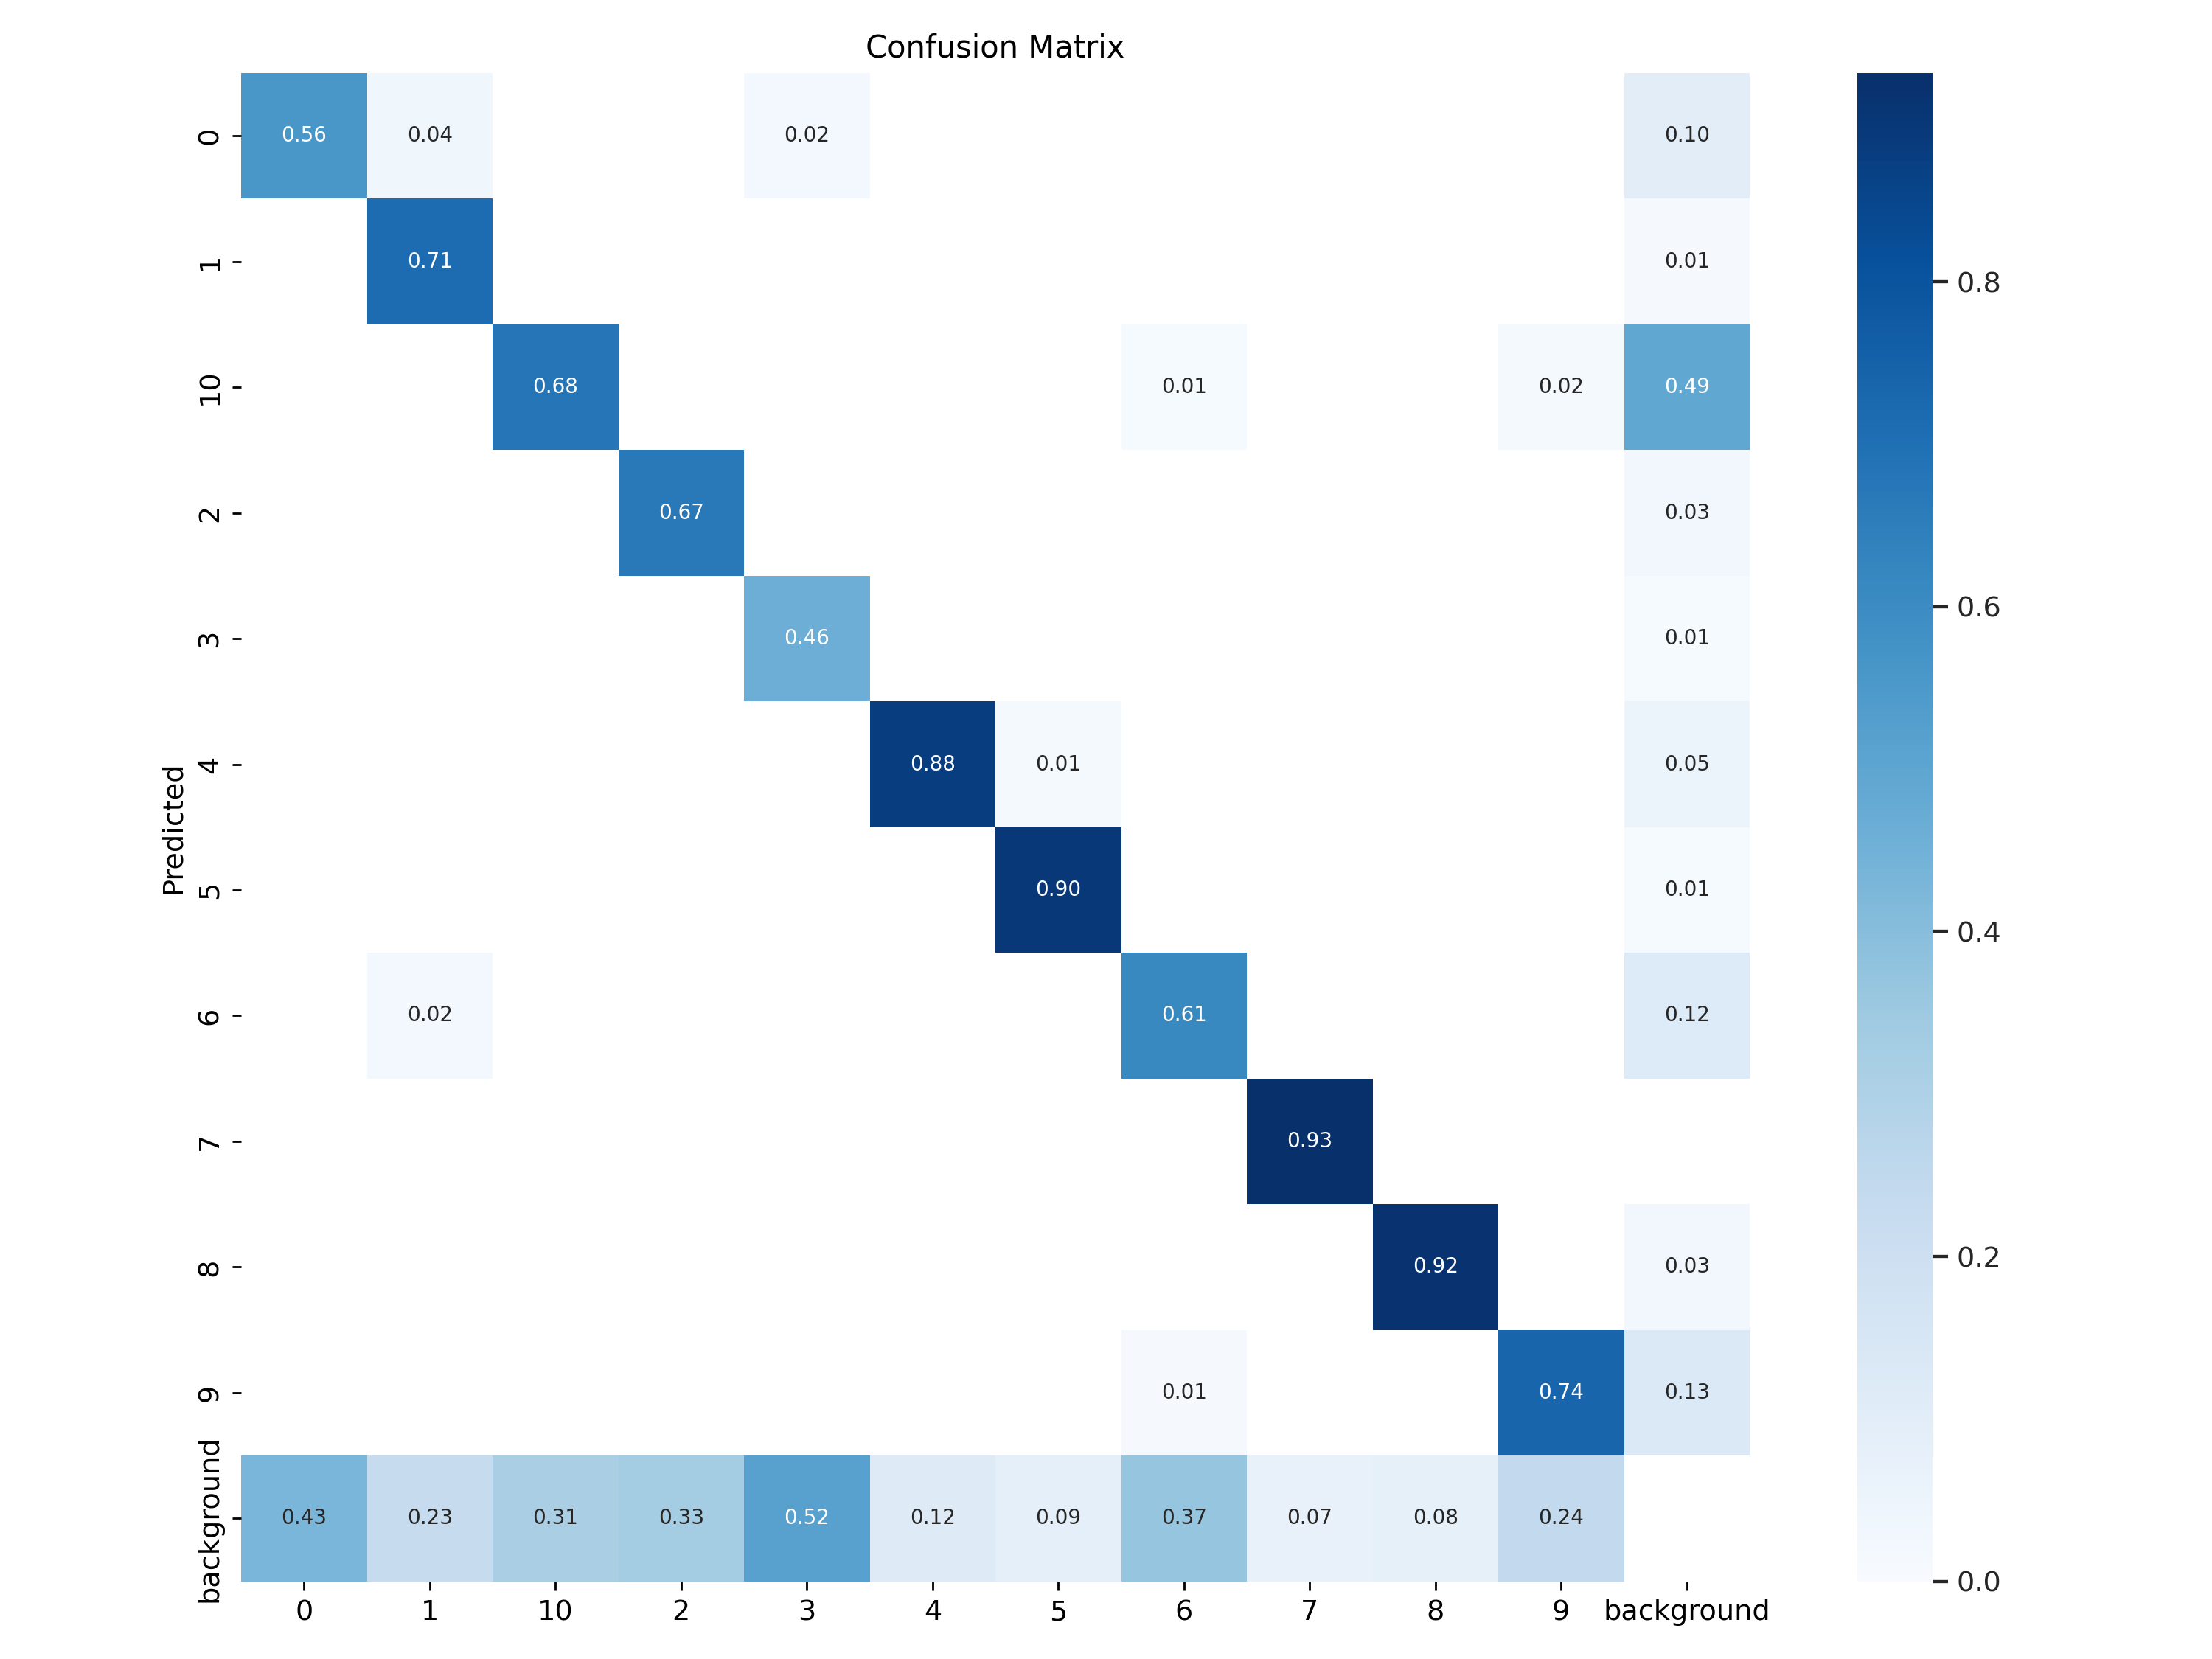

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/confusion_matrix.png", width=1000)

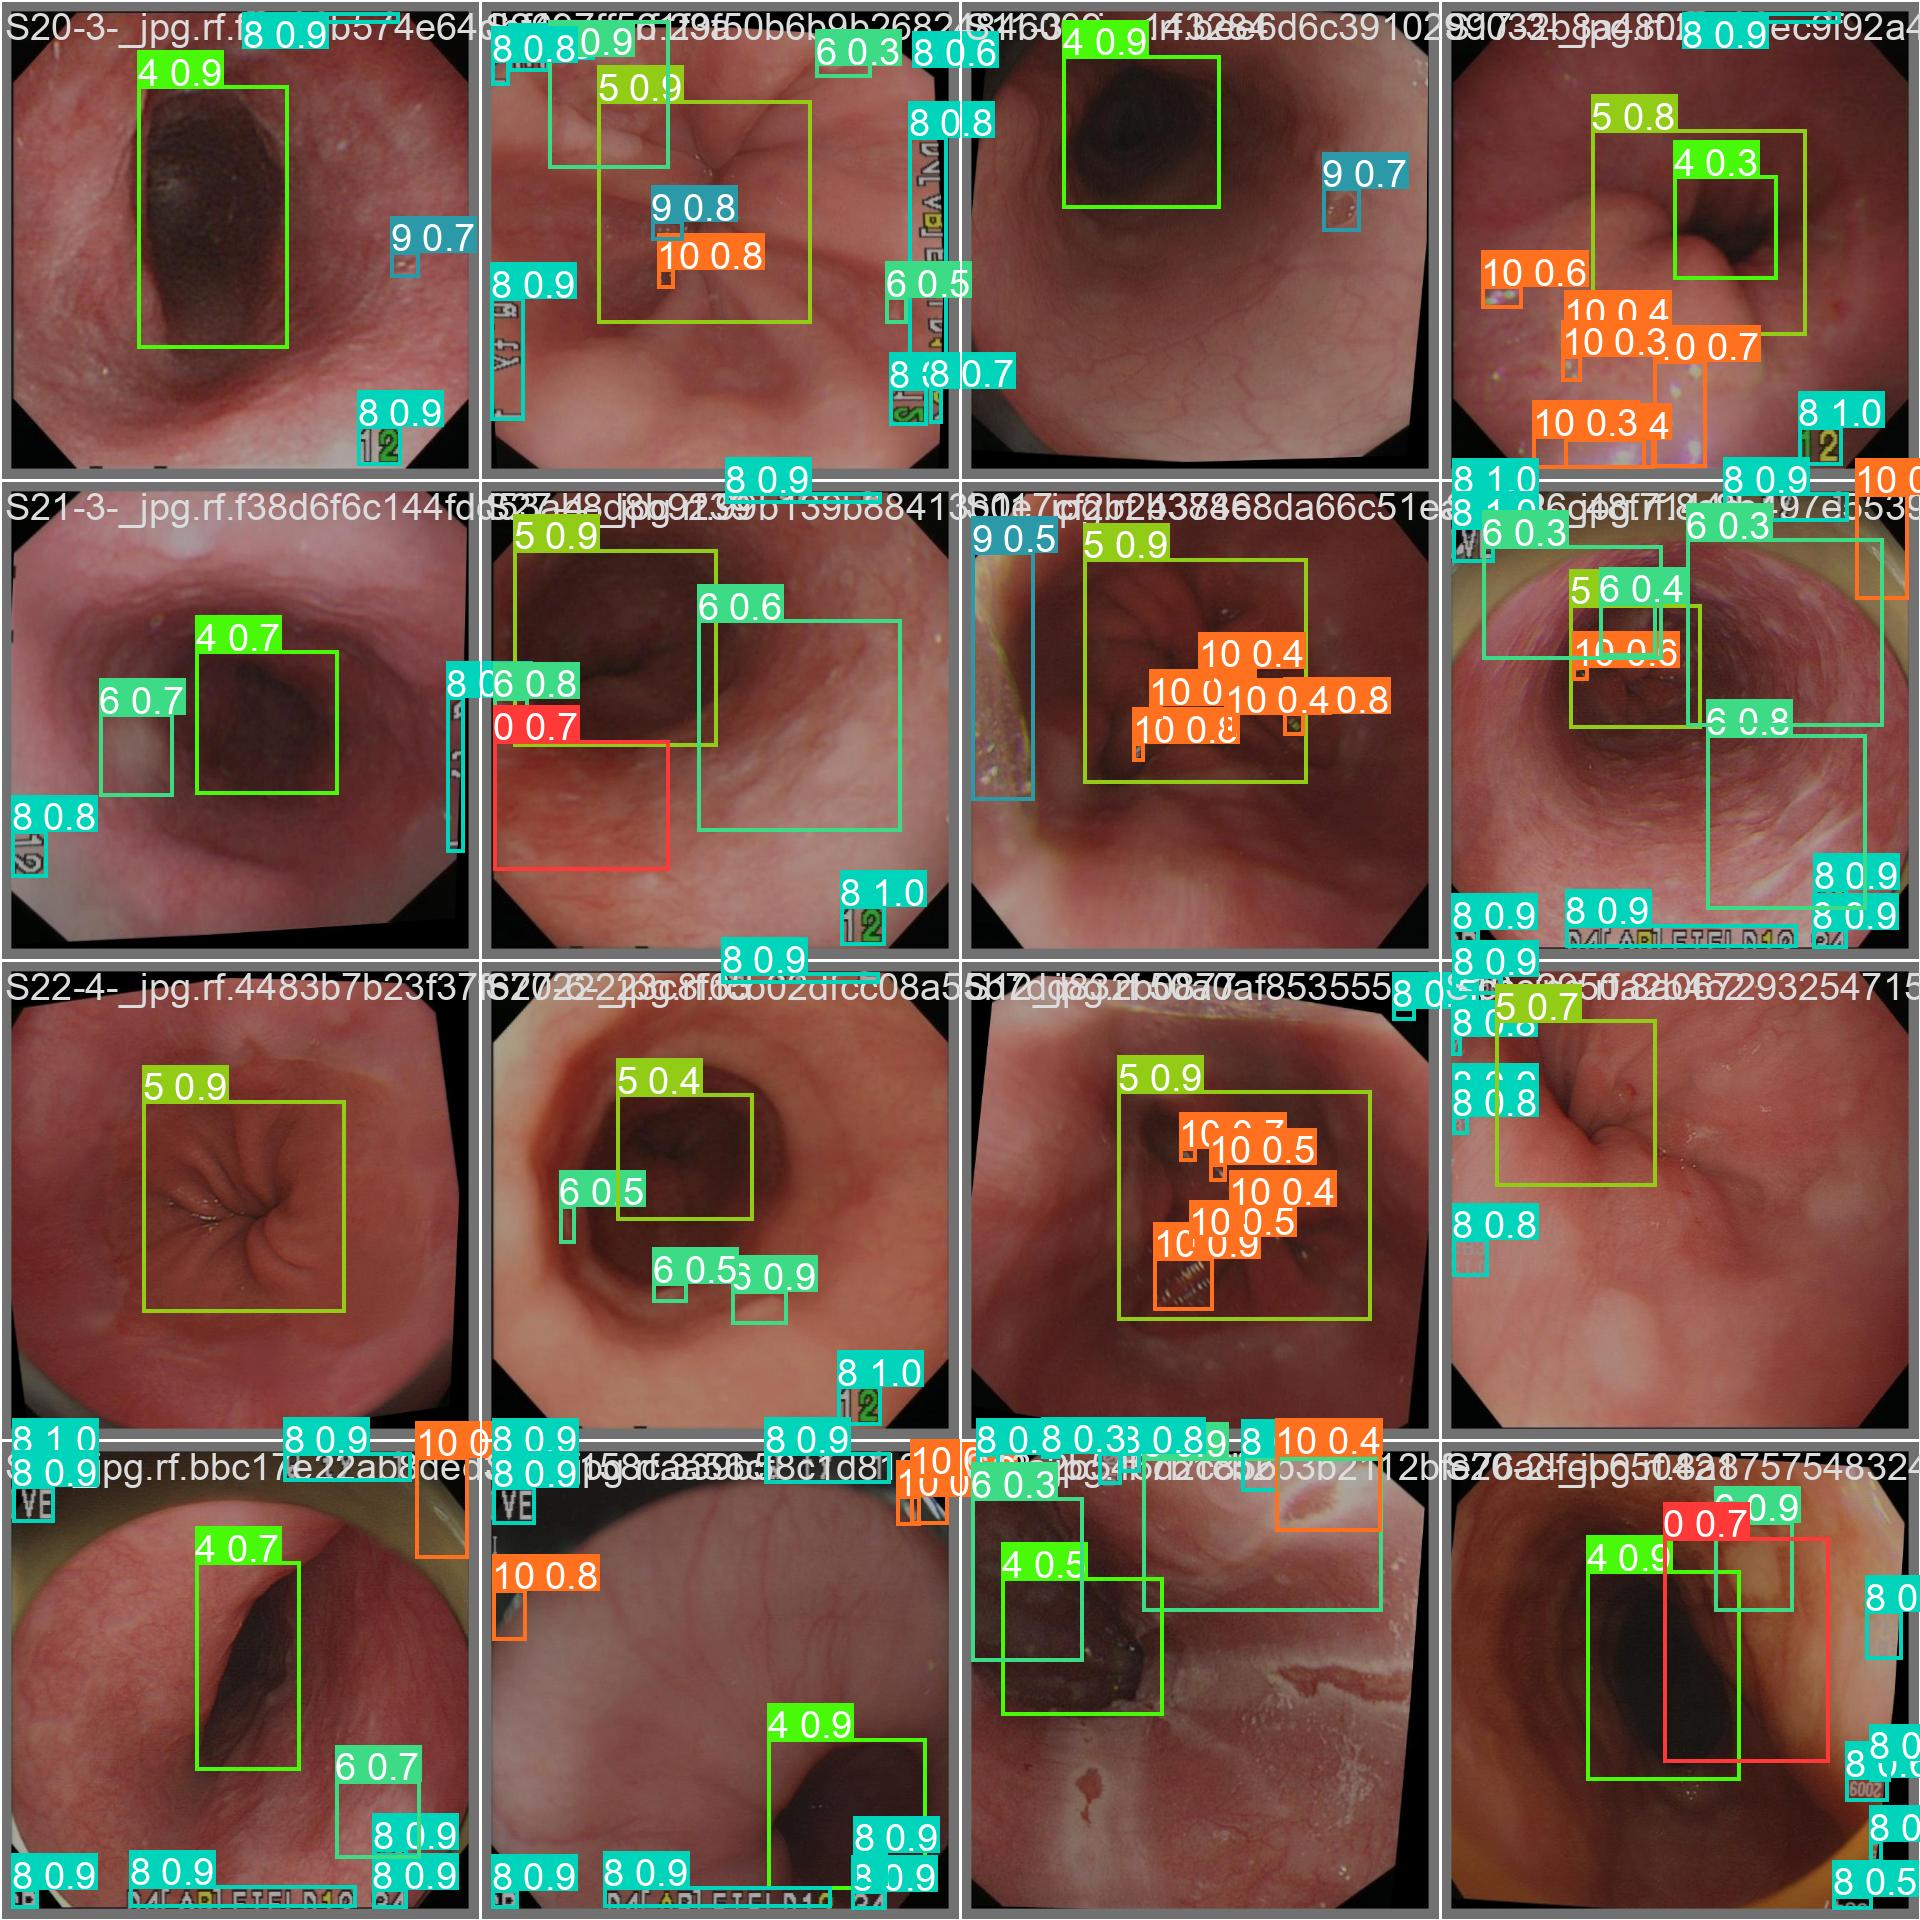

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/val_batch0_pred.jpg", width=1000)

In [14]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 32 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights /content/best.pt

/content/yolov9
val: data=/content/yolov9/Kaohsiung_SAVE-3/data.yaml, weights=['/content/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that coul

In [13]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 32 --conf 0.01 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights /content/best.pt

/content/yolov9
val: data=/content/yolov9/Kaohsiung_SAVE-3/data.yaml, weights=['/content/best.pt'], batch_size=32, imgsz=640, conf_thres=0.01, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
WARNING ⚠️ confidence threshold 0.01 > 0.001 produces invalid results
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights

## Validate Custom Model

In [9]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 32 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights /content/best.pt

/content/yolov9
val: data=/content/yolov9/Kaohsiung_SAVE-3/data.yaml, weights=['/content/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that coul

In [15]:
import shutil

# Replace '/path/to/folder' with the actual path to your folder
shutil.make_archive('/content/yolov9/runs/valV9SAVE', 'zip', '/content/yolov9/runs/val')

from google.colab import files

# Replace 'folder_name.zip' with the actual name of your zip file
files.download('/content/yolov9/runs/valV9SAVE.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Inference with Custom Model

In [ ]:
!python detect.py \
--img 1280 --conf 0.1 --device 0 \
--weights {HOME}/yolov9/runs/train/exp/weights/best.pt \
--source {dataset.location}/test/images

detect: weights=['/content/yolov9/runs/train/exp/weights/best.pt'], source=/content/yolov9/Kaohsiung-1/test/images, data=data/coco128.yaml, imgsz=[1280, 1280], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.3.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

Fusing layers... 
gelan-c summary: 467 layers, 25419441 parameters, 0 gradients, 102.5 GFLOPs
image 1/413 /content/yolov9/Kaohsiung-1/test/images/08888710-2-_jpg.rf.566a584e88ddeb42f76c54adabf249f6.jpg: 1280x1280 1 4, 1 6, 2 9s, 17.4ms
image 2/413 /content/yolov9/Kaohsiung-1/test/images/17491749_20190422_ES_0_10_10_jpg.rf.be93291704172820f03a71bfd4953350.jpg: 1280x1280 2 0s, 2 1s, 2 10s, 1 4,

**NOTE:** Just like behore, the inference results have been saved in the appropriate directory inside `{HOME}/yolov9/runs/detect/`. Let's examine few of those results.

In [ ]:
import glob

from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/yolov9/runs/detect/exp3/*.jpg')[:2]:
      display(Image(filename=image_path, width=600))

In [ ]:
!python detect.py --weights /content/best.pt --img 640 --conf 0.25 --source /content/yolov9/Kaohsiung-1/test/images --save-txt --save-conf

detect: weights=['/content/best.pt'], source=/content/yolov9/Kaohsiung-1/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value f

In [ ]:
!python detect.py --weights /content/best.pt --img 640 --conf 0.25 --source /content/yolov9/Kaohsiung-1/test/images --save-txt --save-conf

detect: weights=['/content/best.pt'], source=/content/yolov9/Kaohsiung-1/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value f

Mismatched lengths for REC20201119-123745320__008064_jpg.rf.b2acbc4ff59e0142452f29a4cd287d34.txt: Ground truth - 4, Predictions - 1
Mismatched lengths for REC20200923-081300961__005452_jpg.rf.092686c9845438ec029329c9c423ce9d.txt: Ground truth - 15, Predictions - 16
Mismatched lengths for REC20200804-103743676__000395_jpg.rf.e767995a8753bc1d13b6d2b4718093ec.txt: Ground truth - 9, Predictions - 10
Mismatched lengths for S46-2-_jpg.rf.8b1d9f005a94f8adc2f5b92c7713172b.txt: Ground truth - 11, Predictions - 9
Mismatched lengths for S03-5-_jpg.rf.9347ae9fc35f20a3cf02d013d136182a.txt: Ground truth - 15, Predictions - 14
Mismatched lengths for REC20200923-081300961__002374_jpg.rf.92b7a3b4f0db5a255849c647b1884100.txt: Ground truth - 6, Predictions - 8
Mismatched lengths for REC20200917-102257151__000464_jpg.rf.97f0ea14668daae5c6eecde0590e24ee.txt: Ground truth - 4, Predictions - 5
Mismatched lengths for REC20200921-105304055__000054_jpg.rf.9213c8d8c58296036133aaad3bb690d4.txt: Ground truth - 4, 

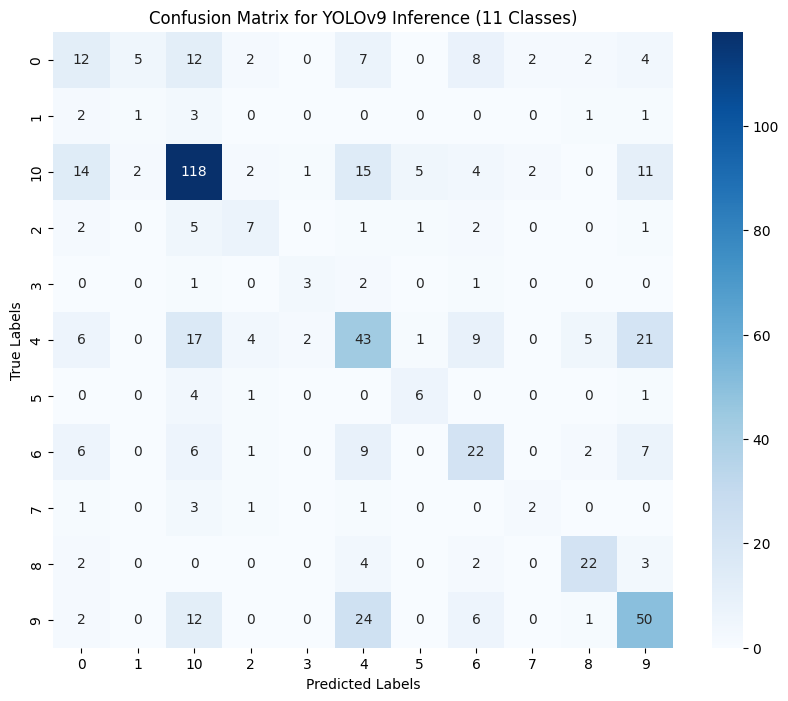

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Path to ground truth and predictions (adjust paths as necessary)
ground_truth_path = '/content/yolov9/Kaohsiung-1/test/labels'
predictions_path = '/content/yolov9/runs/detect/exp3/labels'

# Update class names based on data.yaml
class_names = ['0', '1', '10', '2', '3', '4', '5', '6', '7', '8', '9']

# Initialize lists to store labels
ground_truth_labels = []
predicted_labels = []

# Function to read labels from txt files
def read_labels(file_path):
    labels = []
    with open(file_path, 'r') as f:
        for line in f:
            label = int(line.split()[0])  # Class ID is the first element
            labels.append(label)
    return labels

# Loop through ground truth files
for filename in os.listdir(ground_truth_path):
    if filename.endswith('.txt'):
        # Read ground truth labels
        gt_labels = read_labels(os.path.join(ground_truth_path, filename))

        # Read predicted labels (if available)
        pred_file = os.path.join(predictions_path, filename)
        if os.path.exists(pred_file):
            pred_labels = read_labels(pred_file)
            # Ensure both lists have the same length for comparison
            if len(gt_labels) == len(pred_labels):
                ground_truth_labels.extend(gt_labels)
                predicted_labels.extend(pred_labels)
            else:
                # Handle cases with mismatched lengths (e.g., skip file)
                print(f"Mismatched lengths for {filename}: Ground truth - {len(gt_labels)}, Predictions - {len(pred_labels)}")
                continue
        else:
            print(f"No prediction file found for {filename}")
            continue

# Compute the confusion matrix for the 11 classes
cm = confusion_matrix(ground_truth_labels, predicted_labels, labels=list(range(11)))

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for YOLOv9 Inference (11 Classes)')
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

# Define the confusion matrix
confusion_matrix = np.array([
    [12, 5, 12, 2, 0, 7, 0, 8, 2, 2, 4],
    [2, 1, 3, 0, 0, 0, 0, 0, 1, 1, 0],
    [14, 2, 118, 2, 1, 15, 5, 4, 2, 0, 11],
    [2, 0, 5, 7, 0, 1, 1, 2, 0, 0, 1],
    [0, 0, 1, 0, 3, 2, 0, 1, 0, 0, 0],
    [6, 0, 17, 4, 2, 43, 1, 9, 0, 5, 21],
    [0, 0, 4, 1, 0, 0, 6, 0, 0, 0, 1],
    [6, 6, 6, 1, 0, 9, 0, 22, 0, 2, 7],
    [7, 3, 3, 0, 1, 0, 1, 2, 0, 0, 0],
    [2, 0, 0, 0, 0, 4, 0, 2, 0, 22, 3],
    [2, 12, 0, 0, 24, 6, 0, 1, 0, 50, 0]
])

# Calculate precision, recall, and F1 score
precision, recall, f1, _ = precision_recall_fscore_support(
    np.argmax(confusion_matrix, axis=0),  # True labels
    np.argmax(confusion_matrix, axis=1),  # Predicted labels
    average='macro'  # Calculate metrics globally by averaging
)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")


Precision: 0.5556
Recall: 0.5556
F1 Score: 0.5370


Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

# Define the confusion matrix
confusion_matrix = np.array([
    [12, 5, 12, 2, 0, 7, 0, 8, 2, 2, 4],
    [2, 1, 3, 0, 0, 0, 0, 0, 1, 1, 0],
    [14, 2, 118, 2, 1, 15, 5, 4, 2, 0, 11],
    [2, 0, 5, 7, 0, 1, 1, 2, 0, 0, 1],
    [0, 0, 1, 0, 3, 2, 0, 1, 0, 0, 0],
    [6, 0, 17, 4, 2, 43, 1, 9, 0, 5, 21],
    [0, 0, 4, 1, 0, 0, 6, 0, 0, 0, 1],
    [6, 6, 6, 1, 0, 9, 0, 22, 0, 2, 7],
    [7, 3, 3, 0, 1, 0, 1, 2, 0, 0, 0],
    [2, 0, 0, 0, 0, 4, 0, 2, 0, 22, 3],
    [2, 12, 0, 0, 24, 6, 0, 1, 0, 50, 0]
])

# Calculate the true positives, false positives, false negatives
true_positives = np.diag(confusion_matrix)
false_positives = np.sum(confusion_matrix, axis=0) - true_positives
false_negatives = np.sum(confusion_matrix, axis=1) - true_positives

# Calculate precision, recall for each class
precision_per_class = true_positives / (true_positives + false_positives)
recall_per_class = true_positives / (true_positives + false_negatives)
f1_per_class = 2 * (precision_per_class * recall_per_class) / (precision_per_class + recall_per_class)

# Handle cases where precision, recall might be undefined
precision_per_class = np.nan_to_num(precision_per_class)
recall_per_class = np.nan_to_num(recall_per_class)
f1_per_class = np.nan_to_num(f1_per_class)

# Display results
for i, (precision, recall, f1) in enumerate(zip(precision_per_class, recall_per_class, f1_per_class)):
    print(f"Class {i}: Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}")


Class 0: Precision: 0.2264, Recall: 0.2222, F1 Score: 0.2243
Class 1: Precision: 0.0345, Recall: 0.1250, F1 Score: 0.0541
Class 2: Precision: 0.6982, Recall: 0.6782, F1 Score: 0.6880
Class 3: Precision: 0.4118, Recall: 0.3684, F1 Score: 0.3889
Class 4: Precision: 0.0968, Recall: 0.4286, F1 Score: 0.1579
Class 5: Precision: 0.4943, Recall: 0.3981, F1 Score: 0.4410
Class 6: Precision: 0.4286, Recall: 0.5000, F1 Score: 0.4615
Class 7: Precision: 0.4314, Recall: 0.3729, F1 Score: 0.4000
Class 8: Precision: 0.0000, Recall: 0.0000, F1 Score: 0.0000
Class 9: Precision: 0.2683, Recall: 0.6667, F1 Score: 0.3826
Class 10: Precision: 0.0000, Recall: 0.0000, F1 Score: 0.0000


<ipython-input-1-9f4281f6b05a>:27: RuntimeWarning: invalid value encountered in divide
  f1_per_class = 2 * (precision_per_class * recall_per_class) / (precision_per_class + recall_per_class)


In [ ]:
!pip install ultralytics
!pip install torch torchvision torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 873.1/873.1 kB 46.8 MB/s eta 0:00:00


In [ ]:
!pip install --upgrade ultralytics


In [ ]:
!zip -r /content/yolov9/runs/train/exp.zip /content/yolov9/runs/train/exp

  adding: content/yolov9/runs/train/exp/ (stored 0%)
  adding: content/yolov9/runs/train/exp/hyp.yaml (deflated 42%)
  adding: content/yolov9/runs/train/exp/train_batch2.jpg (deflated 5%)
  adding: content/yolov9/runs/train/exp/R_curve.png (deflated 5%)
  adding: content/yolov9/runs/train/exp/labels.jpg (deflated 24%)
  adding: content/yolov9/runs/train/exp/train_batch0.jpg (deflated 4%)
  adding: content/yolov9/runs/train/exp/val_batch1_pred.jpg (deflated 9%)
  adding: content/yolov9/runs/train/exp/train_batch1.jpg (deflated 8%)
  adding: content/yolov9/runs/train/exp/F1_curve.png (deflated 5%)
  adding: content/yolov9/runs/train/exp/P_curve.png (deflated 5%)
  adding: content/yolov9/runs/train/exp/val_batch2_pred.jpg (deflated 11%)
  adding: content/yolov9/runs/train/exp/weights/ (stored 0%)
  adding: content/yolov9/runs/train/exp/weights/last.pt (deflated 8%)
  adding: content/yolov9/runs/train/exp/weights/best_striped.pt (deflated 9%)
  adding: content/yolov9/runs/train/exp/weights

In [ ]:
from google.colab import files
files.download("/content/yolov9/runs/train/exp.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>